# MAI391 — Computer Project, Nhóm 1
## Hồi quy tuyến tính bằng hạ gradient trên dữ liệu chất lượng rượu vang đỏ

Notebook này chạy lại **toàn bộ Mục 3–5** của `BaoCao.pdf`: lõi thuật toán (chỉ dùng `numpy`), kiểm thử tăng dần,
điều kiện số, khảo sát bước học $\gamma$, khảo sát quán tính, đối chiếu `scikit-learn`.
Ô cuối cùng **đối chiếu tự động từng con số** với báo cáo.

**Mô hình.** $L(\boldsymbol\theta)=\frac1{2N}\|\mathbf y-\mathbf X\boldsymbol\theta\|^2$, 
$\nabla L=\frac1N\mathbf X^\top(\mathbf X\boldsymbol\theta-\mathbf y)$, $\mathbf H=\frac1N\mathbf X^\top\mathbf X$,
hạ gradient $\boldsymbol\theta_{t+1}=\boldsymbol\theta_t-\gamma\nabla L(\boldsymbol\theta_t)$, hội tụ $\iff 0<\gamma<2/\lambda_{\max}$.

**Tái lập.** Mọi ngẫu nhiên đều cố định hạt giống (`SEED = 42`); $\boldsymbol\theta_0=\mathbf 0$.

In [1]:
import os, sys, numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
CANDIDATES = ["data/winequality-red.csv", "winequality-red.csv", "../data/winequality-red.csv",
              "/content/winequality-red.csv", "/content/data/winequality-red.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Khong thay winequality-red.csv. Dat file vao ./data/ hoac cung thu muc voi notebook.")
print("Du lieu:", DATA_PATH)

Du lieu: ../data/winequality-red.csv


## 3. Cài đặt — lõi thuật toán (chỉ dùng numpy)

Tương ứng `src/gd_linreg.py`. Không dùng `sklearn` ở phần lõi.

In [2]:
"""Loi thuat toan: hoi quy tuyen tinh bang ha gradient (chi dung numpy)."""
import numpy as np


def load_wine(path):
    d = np.genfromtxt(path, delimiter=";", skip_header=1)
    with open(path) as f:
        names = [s.strip('"') for s in f.readline().strip().split(";")]
    return d[:, :-1], d[:, -1], names[:-1]


def train_test_split(X, y, test_size=0.2, seed=42):
    """Hoan vi ngau nhien voi rng(seed); lay `test_size` dau lam tap kiem tra."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    n_test = int(round(test_size * len(y)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]


def standardize_fit(X):
    return X.mean(axis=0), X.std(axis=0)


def standardize_apply(X, m, s):
    return (X - m) / s


def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])


def loss(theta, X, y):
    r = X @ theta - y
    return 0.5 * np.mean(r ** 2)         


def grad(theta, X, y):
    return X.T @ (X @ theta - y) / X.shape[0]   


def hessian(X):
    return X.T @ X / X.shape[0]


def hessian_spectrum(X):
    ev = np.linalg.eigvalsh(hessian(X))
    return ev.max(), ev.min(), ev.max() / ev.min()


def normal_equation(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)      


def gradient_descent(X, y, gamma, beta=0.0, T=5000, eps=0.0,
                     theta_star=None, tol=None):
    """Thuat toan 1. beta=0: GD thuong. Tra ve theta va lich su."""
    N, P = X.shape
    theta = np.zeros(P)
    v = np.zeros(P)
    hist = {"loss": [loss(theta, X, y)], "dist": [], "iters_to_tol": None,
            "diverged": False}
    if theta_star is not None:
        hist["dist"].append(np.linalg.norm(theta - theta_star))
    for t in range(1, T + 1):
        g = grad(theta, X, y)
        if np.linalg.norm(g) < eps:
            break
        v = beta * v - gamma * g
        theta = theta + v
        L = loss(theta, X, y)
        hist["loss"].append(L)
        if theta_star is not None:
            d = np.linalg.norm(theta - theta_star)
            hist["dist"].append(d)
            if tol is not None and hist["iters_to_tol"] is None and d < tol:
                hist["iters_to_tol"] = t
        if not np.isfinite(L) or L > 1e30:
            hist["diverged"] = True
            break
    return theta, hist


def heavy_ball_params(lmax, lmin):
    kappa = lmax / lmin
    gamma = 4.0 / (np.sqrt(lmax) + np.sqrt(lmin)) ** 2
    beta = ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** 2
    return gamma, beta


def mse(y, yhat):
    return np.mean((y - yhat) ** 2)


def r2(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


# ---------------------------------------------------------------------------
# Cac ham bo tro cho kiem thu va phan tich (van chi dung numpy)
# ---------------------------------------------------------------------------
SEED = 42            
SEED_GRADCHECK = 0   
EPS_FD = 1e-5        

def gradient_check(X, y, seed=SEED_GRADCHECK, eps=EPS_FD):
    """Sai khac lon nhat giua grad giai tich (3) va sai phan huu han trung tam.
    theta ~ N(0, I) sinh boi default_rng(seed)."""
    th = np.random.default_rng(seed).normal(size=X.shape[1])
    I = np.eye(len(th))
    fd = np.array([(loss(th + eps * I[i], X, y) - loss(th - eps * I[i], X, y)) / (2 * eps)
                   for i in range(len(th))])
    return np.abs(fd - grad(th, X, y)).max()


def make_synthetic(seed=SEED, N=500, D=11, sigma=0.05):
    """Du lieu tong hop y = X theta_true + eps.
    Thu tu sinh (default_rng(seed)): X_raw ~ N(0,1) (N x D), theta_true ~ N(0,1) (D+1),
    nhieu eps ~ N(0, sigma^2) (N). Tra ve (X co cot 1, y, theta_true)."""
    rng = np.random.default_rng(seed)
    X = add_bias(rng.normal(size=(N, D)))
    theta_true = rng.normal(size=D + 1)
    y = X @ theta_true + sigma * rng.normal(size=N)
    return X, y, theta_true


def heavy_ball_root_modulus(gamma, beta, lam):
    """Mo-dun lon nhat cua nghiem z^2 - (1+beta-gamma*lam) z + beta = 0."""
    b = 1 + beta - gamma * lam
    disc = b * b - 4 * beta
    if disc <= 0:
        return np.sqrt(beta)
    r = np.sqrt(disc)
    return max(abs((b + r) / 2), abs((b - r) / 2))


def heavy_ball_discriminant(gamma, beta, lam):
    return (1 + beta - gamma * lam) ** 2 - 4 * beta


def heavy_ball_gamma_limit(lmax, beta):
    """Dieu kien on dinh heavy-ball: 0 < gamma < 2(1+beta)/lambda_max."""
    return 2 * (1 + beta) / lmax


def poly2_features(X):
    """Dac trung bac 2: x_i, x_i*x_j (i<=j). Khong gom cot 1."""
    n, d = X.shape
    cols = [X] + [(X[:, i] * X[:, j])[:, None] for i in range(d) for j in range(i, d)]
    return np.hstack(cols)

## 4.1 Dữ liệu, chia dữ liệu, chỉ số

In [3]:
X, y, names = load_wine(DATA_PATH)
print("X:", X.shape, " y:", y.shape, " thieu gia tri:", int(np.isnan(X).sum() + np.isnan(y).sum()))

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=SEED)
print("Huan luyen:", Xtr.shape[0], " Kiem tra:", Xte.shape[0])

baseline = mse(yte, ytr.mean())
print(f"Moc so sanh (du doan bang trung binh nhan): MSE kiem tra = {baseline:.4f}")

m, s = standardize_fit(Xtr)
Ztr = add_bias(standardize_apply(Xtr, m, s))
Zte = add_bias(standardize_apply(Xte, m, s))
# Du lieu tho (chi them he so chan)
Rtr, Rte = add_bias(Xtr), add_bias(Xte)

theta_star = normal_equation(Ztr, ytr)     
lmax, lmin, kappa = hessian_spectrum(Ztr)
print(f"Chuan hoa: lambda_max={lmax:.4f}  lambda_min={lmin:.4f}  kappa={kappa:.2f}")
print(f"L(theta*) = {loss(theta_star, Ztr, ytr):.7f}   ||theta*|| = {np.linalg.norm(theta_star):.3f}")

X: (1599, 11)  y: (1599,)  thieu gia tri: 0
Huan luyen: 1279  Kiem tra: 320
Moc so sanh (du doan bang trung binh nhan): MSE kiem tra = 0.6040
Chuan hoa: lambda_max=3.0839  lambda_min=0.0597  kappa=51.63
L(theta*) = 0.2112205   ||theta*|| = 5.675


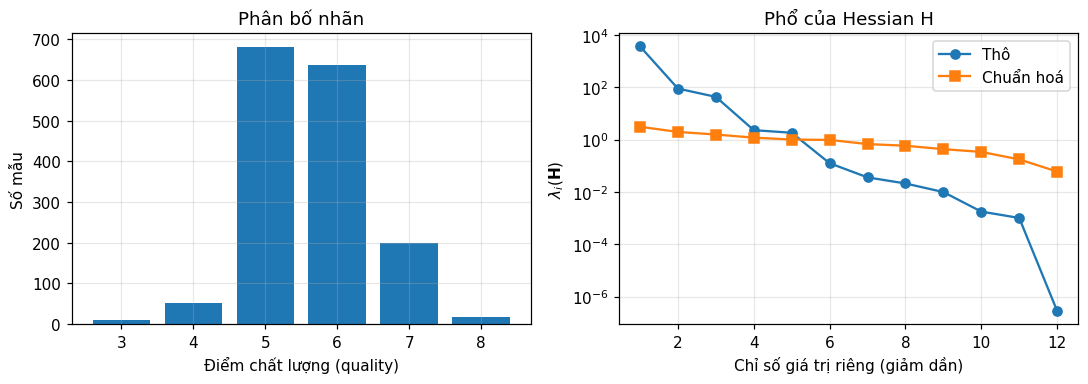

Ty le nhan 5 hoac 6: 0.8249


In [4]:
ev_raw = np.sort(np.linalg.eigvalsh(hessian(Rtr)))[::-1]
ev_std = np.sort(np.linalg.eigvalsh(hessian(Ztr)))[::-1]
vals, cnts = np.unique(y, return_counts=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(vals, cnts); ax[0].set_xlabel("Điểm chất lượng (quality)"); ax[0].set_ylabel("Số mẫu")
ax[0].set_title("Phân bố nhãn")
idx = np.arange(1, len(ev_raw) + 1)
ax[1].semilogy(idx, np.abs(ev_raw), "o-", label="Thô")
ax[1].semilogy(idx, ev_std, "s-", label="Chuẩn hoá")
ax[1].set_xlabel("Chỉ số giá trị riêng (giảm dần)"); ax[1].set_ylabel(r"$\lambda_i(\mathbf{H})$")
ax[1].set_title("Phổ của Hessian H"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Ty le nhan 5 hoac 6:", np.mean((y == 5) | (y == 6)).round(4))

## 4.2 Kiểm thử theo thứ tự tăng dần

(0) ví dụ nhỏ giải tay → (1) kiểm tra gradient → (2) dữ liệu tổng hợp → (3) dữ liệu thật. Toàn bộ hạt giống và phân phối được ghi rõ để tái lập.

In [5]:
x0 = np.array([0., 1., 2., 3.]); y0 = np.array([1., 3., 4., 8.]); X0 = add_bias(x0[:, None])
th_hand = np.array([0.7, 2.2])
l0max, l0min, _ = hessian_spectrum(X0)
th0, _ = gradient_descent(X0, y0, 1 / l0max, T=5000)
print("(0) Giai tay      :", th_hand)
print("    Chuan tac     :", normal_equation(X0, y0))
print("    Ha gradient   :", th0, f"  |GD - giai tay|_inf = {np.abs(th0 - th_hand).max():.1e}")
_, hd = gradient_descent(X0, y0, 2.05 / l0max, T=5000)
print(f"    gamma = 2.05/lmax (> 2/lmax) phan ky: {hd['diverged']}")

gc_err = gradient_check(Ztr, ytr)
print(f"(1) Kiem tra gradient: sai khac lon nhat = {gc_err:.2e}")

Xs, ys, th_true = make_synthetic(seed=SEED, N=500, D=11, sigma=0.05)
th_ne = normal_equation(Xs, ys); ls_max = hessian_spectrum(Xs)[0]
th_gd, _ = gradient_descent(Xs, ys, 1 / ls_max, T=20000)
syn_gd_ne = np.abs(th_gd - th_ne).max(); syn_vs_true = np.abs(th_ne - th_true).max()
print(f"(2) Tong hop: |GD - chuan tac|_inf = {syn_gd_ne:.2e}")
print(f"    |chuan tac - theta_true|_inf = {syn_vs_true:.4f}   (sai so thong ke sigma/sqrt(N) = {0.05/np.sqrt(500):.4f})")
print("    -> GD trung nghiem chuan tac cua chinh du lieu do; chenh so voi theta_true la sai so lay mau, khong phai loi thuat toan.")

print(f"(3) Du lieu that: rank(X) = {np.linalg.matrix_rank(Ztr)} = D+1 = 12; lambda_min = {lmin:.4f} > 0  ->  H xac dinh duong, cuc tieu duy nhat")

(0) Giai tay      : [0.7 2.2]
    Chuan tac     : [0.7 2.2]
    Ha gradient   : [0.7 2.2]   |GD - giai tay|_inf = 1.6e-15
    gamma = 2.05/lmax (> 2/lmax) phan ky: True
(1) Kiem tra gradient: sai khac lon nhat = 3.21e-10
(2) Tong hop: |GD - chuan tac|_inf = 8.88e-16
    |chuan tac - theta_true|_inf = 0.0037   (sai so thong ke sigma/sqrt(N) = 0.0022)
    -> GD trung nghiem chuan tac cua chinh du lieu do; chenh so voi theta_true la sai so lay mau, khong phai loi thuat toan.
(3) Du lieu that: rank(X) = 12 = D+1 = 12; lambda_min = 0.0597 > 0  ->  H xac dinh duong, cuc tieu duy nhat


## 4.3 Điều kiện số: dữ liệu thô và dữ liệu chuẩn hoá

,lambda_max,lambda_min,kappa,gamma_max = 2/lambda_max
Thô,3.63e+03,2.82e-07,1.29e+10,0.000551
Chuẩn hoá,3.08,0.0597,51.6,0.649


Chuan hoa giam kappa khoang 2.49e+08 lan

Du lieu chuan hoa: ||theta_t - theta*|| < 1e-6 sau 507 vong
Du lieu tho (T=5000): L-L* = 0.030, ||theta_T - theta*|| = 57.4, MSE kiem tra = 0.5001 (toi uu: 0.4018)
Can ly thuyet kappa*ln(||e0||/eps) cho du lieu tho: 2.30e+11 vong


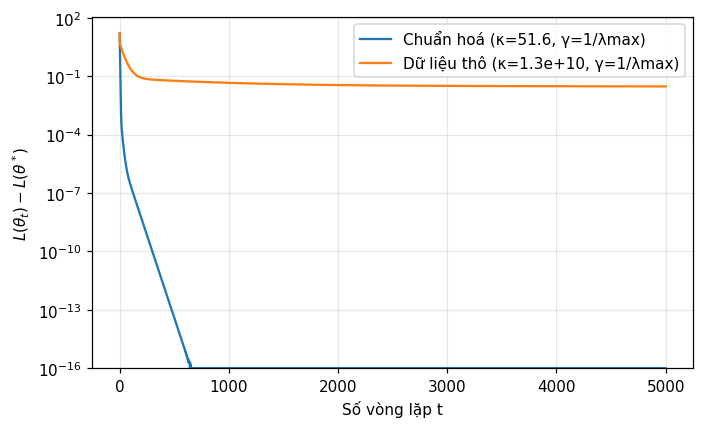

In [6]:
theta_star_raw = normal_equation(Rtr, ytr)
lmax_r, lmin_r, kappa_r = hessian_spectrum(Rtr)

tab3 = pd.DataFrame({
    "lambda_max": [lmax_r, lmax], "lambda_min": [lmin_r, lmin],
    "kappa": [kappa_r, kappa], "gamma_max = 2/lambda_max": [2/lmax_r, 2/lmax]},
    index=["Thô", "Chuẩn hoá"])
display(tab3.style.format("{:.3g}"))
print(f"Chuan hoa giam kappa khoang {kappa_r/kappa:.2e} lan")

TOL = 1e-6
th_std, h_std = gradient_descent(Ztr, ytr, 1/lmax, T=5000, theta_star=theta_star, tol=TOL)
th_raw, h_raw = gradient_descent(Rtr, ytr, 1/lmax_r, T=5000, theta_star=theta_star_raw, tol=TOL)
Lstar_std, Lstar_raw = loss(theta_star, Ztr, ytr), loss(theta_star_raw, Rtr, ytr)

print(f"\nDu lieu chuan hoa: ||theta_t - theta*|| < 1e-6 sau {h_std['iters_to_tol']} vong")
raw_gap = h_raw['loss'][-1] - Lstar_raw
raw_dist = h_raw['dist'][-1]
raw_mse = mse(yte, Rte @ th_raw); raw_opt = mse(yte, Rte @ theta_star_raw)
print(f"Du lieu tho (T=5000): L-L* = {raw_gap:.3f}, ||theta_T - theta*|| = {raw_dist:.1f}, "
      f"MSE kiem tra = {raw_mse:.4f} (toi uu: {raw_opt:.4f})")
print(f"Can ly thuyet kappa*ln(||e0||/eps) cho du lieu tho: {kappa_r*np.log(np.linalg.norm(theta_star_raw)/TOL):.2e} vong")

fig, ax = plt.subplots(figsize=(6.5, 4))
floor = 1e-16
ax.semilogy(np.maximum(np.array(h_std["loss"]) - Lstar_std, floor), label=f"Chuẩn hoá (κ={kappa:.1f}, γ=1/λmax)")
ax.semilogy(np.maximum(np.array(h_raw["loss"]) - Lstar_raw, floor), label=f"Dữ liệu thô (κ={kappa_r:.1e}, γ=1/λmax)")
ax.set_ylim(floor, None); ax.set_xlabel("Số vòng lặp t"); ax.set_ylabel(r"$L(\theta_t)-L(\theta^*)$")
ax.legend(); plt.tight_layout(); plt.show()

## 4.4 Khảo sát bước học $\gamma$ (dữ liệu chuẩn hoá)

L(theta*) = 0.2112205


,gamma,gamma/gamma_max,Giá trị gamma,L(θ_300),Số vòng đến ‖θt−θ*‖<1e-6
0,0.1/λmax,0.050,0.032426,0.21127,5114
1,0.5/λmax,0.250,0.162132,0.211221,1019
2,1.0/λmax,0.500,0.324265,0.21122,507
3,1.9/λmax,0.950,0.616103,0.21122,265
4,1.99/λmax,0.995,0.645287,0.211233,1090
5,2.05/λmax,1.025,0.664743,phân kỳ,—


gamma_opt = 2/(lmax+lmin) = 0.6362 (= 0.981 gamma_max), rho_opt = 0.9620
gamma_opt: can ly thuyet ~ 401 vong, thuc do 285 vong
gamma=1/lmax: can ly thuyet (kappa*ln) ~ 803 vong (||e0||=5.67), thuc do 507 vong


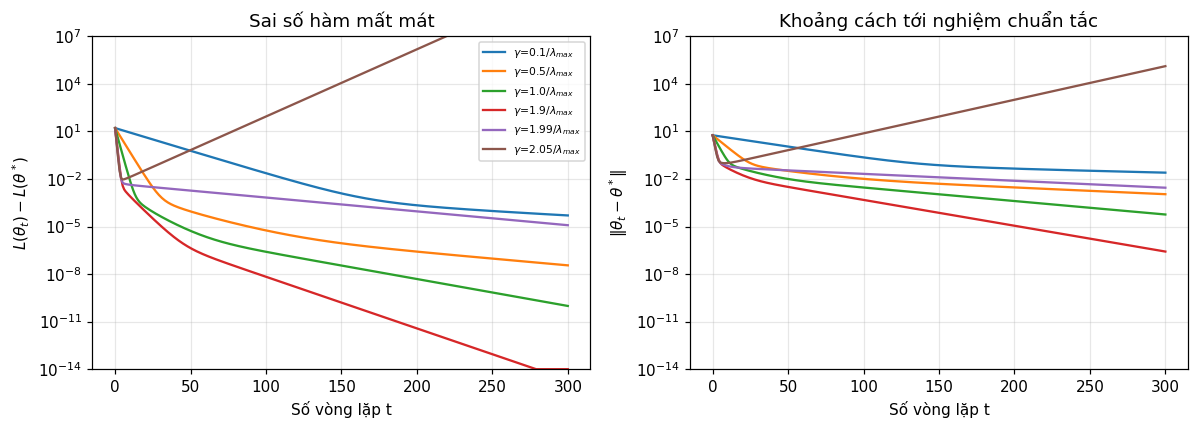

In [7]:
cs = [0.1, 0.5, 1.0, 1.9, 1.99, 2.05]
Lstar = loss(theta_star, Ztr, ytr)
rows, runs = [], {}
for c in cs:
    g = c / lmax
    _, h = gradient_descent(Ztr, ytr, g, T=6000, theta_star=theta_star, tol=TOL)
    runs[c] = h
    L300 = h["loss"][300] if len(h["loss"]) > 300 and not h["diverged"] else None
    rows.append({"gamma": f"{c}/λmax", "gamma/gamma_max": c/2, "Giá trị gamma": g,
                 "L(θ_300)": L300 if L300 is not None else "phân kỳ",
                 "Số vòng đến ‖θt−θ*‖<1e-6": (h["iters_to_tol"] if h["iters_to_tol"] else "—")})
tab4 = pd.DataFrame(rows)
print(f"L(theta*) = {Lstar:.7f}")
display(tab4)

g_opt = 2 / (lmax + lmin); rho_opt = (kappa - 1) / (kappa + 1)
_, h_opt = gradient_descent(Ztr, ytr, g_opt, T=5000, theta_star=theta_star, tol=TOL)
e0 = np.linalg.norm(theta_star)
bound_opt = np.log(e0/TOL) / np.log(1/rho_opt)
bound_inv = kappa * np.log(e0/TOL)
print(f"gamma_opt = 2/(lmax+lmin) = {g_opt:.4f} (= {g_opt/(2/lmax):.3f} gamma_max), rho_opt = {rho_opt:.4f}")
print(f"gamma_opt: can ly thuyet ~ {bound_opt:.0f} vong, thuc do {h_opt['iters_to_tol']} vong")
print(f"gamma=1/lmax: can ly thuyet (kappa*ln) ~ {bound_inv:.0f} vong (||e0||={e0:.2f}), thuc do {runs[1.0]['iters_to_tol']} vong")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in cs:
    h = runs[c]; n = 301
    l = np.array(h["loss"][:n]) - Lstar; d = np.array(h["dist"][:n])
    ax[0].semilogy(np.maximum(l, 1e-14), label=fr"$\gamma$={c}/$\lambda_{{max}}$")
    ax[1].semilogy(np.maximum(d, 1e-14), label=fr"$\gamma$={c}/$\lambda_{{max}}$")
ax[0].set_title("Sai số hàm mất mát"); ax[0].set_ylabel(r"$L(\theta_t)-L(\theta^*)$")
ax[1].set_title("Khoảng cách tới nghiệm chuẩn tắc"); ax[1].set_ylabel(r"$\|\theta_t-\theta^*\|$")
for a in ax: a.set_xlabel("Số vòng lặp t"); a.set_ylim(1e-14, 1e7)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Tiêu chí dừng.** Thuật toán 1 dừng theo $\|g\|<\varepsilon$ (không cần biết $\theta^*$), còn các bảng đếm vòng theo $\|\theta_t-\theta^*\|<10^{-6}$. Vì $g=\mathbf H\,e$ nên $\|e\|\le\|g\|/\lambda_{\min}$: hai tiêu chí liên hệ trực tiếp.

In [8]:
for eps in [1e-3, 1e-5, 1e-7]:
    t, _ = gradient_descent(Ztr, ytr, 1/lmax, T=100000, eps=eps)
    gn, dn = np.linalg.norm(grad(t, Ztr, ytr)), np.linalg.norm(t - theta_star)
    print(f"eps={eps:.0e}:  ||g||={gn:.2e}   ||theta-theta*||={dn:.2e}  <=  ||g||/lmin={gn/lmin:.2e}   [{dn <= gn/lmin + 1e-15}]")

eps=1e-03:  ||g||=9.81e-04   ||theta-theta*||=8.65e-03  <=  ||g||/lmin=1.64e-02   [True]
eps=1e-05:  ||g||=9.81e-06   ||theta-theta*||=1.64e-04  <=  ||g||/lmin=1.64e-04   [True]
eps=1e-07:  ||g||=9.90e-08   ||theta-theta*||=1.66e-06  <=  ||g||/lmin=1.66e-06   [True]


## 4.5 Khảo sát quán tính (heavy-ball)

Heavy-ball toi uu (Polyak): gamma=0.9995, beta=0.571, sqrt(beta)=0.7557  (so voi rho_opt=0.9620)


,Cấu hình,gamma,beta,Vòng đến ‖θt−θ*‖<1e-6 (tối đa 400)
0,"GD thường (β=0, γ=1/λmax)",0.324265,0.000000,>400 (507)
1,"Momentum (β=0.5, γ=1/λmax)",0.324265,0.500000,242
2,"Momentum (β=0.9, γ=1/λmax)",0.324265,0.900000,263
3,Heavy-ball tối ưu (Polyak),0.999501,0.571029,57


Can ly thuyet heavy-ball ~ 56 vong, thuc do 57 vong


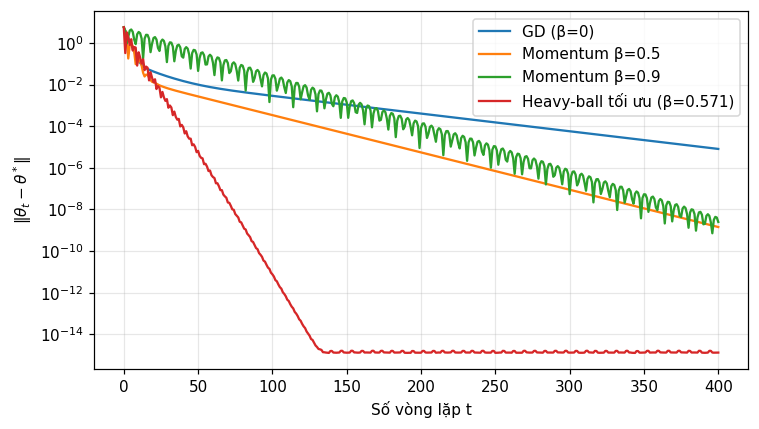

In [9]:
g_hb, b_hb = heavy_ball_params(lmax, lmin)
print(f"Heavy-ball toi uu (Polyak): gamma={g_hb:.4f}, beta={b_hb:.3f}, sqrt(beta)={np.sqrt(b_hb):.4f}  (so voi rho_opt={rho_opt:.4f})")

configs = [("GD thường (β=0, γ=1/λmax)", 1/lmax, 0.0),
           ("Momentum (β=0.5, γ=1/λmax)", 1/lmax, 0.5),
           ("Momentum (β=0.9, γ=1/λmax)", 1/lmax, 0.9),
           ("Heavy-ball tối ưu (Polyak)", g_hb, b_hb)]
rows, mruns = [], []
for name, g, b in configs:
    _, h = gradient_descent(Ztr, ytr, g, b, T=400, theta_star=theta_star, tol=TOL)
    _, h_long = gradient_descent(Ztr, ytr, g, b, T=2000, theta_star=theta_star, tol=TOL)
    mruns.append((name, h))
    it = h["iters_to_tol"]
    rows.append({"Cấu hình": name, "gamma": g, "beta": b,
                 "Vòng đến ‖θt−θ*‖<1e-6 (tối đa 400)": it if it else f">400 ({h_long['iters_to_tol']})"})
tab5 = pd.DataFrame(rows); display(tab5)

hb_bound = np.log(e0/TOL) / np.log(1/np.sqrt(b_hb))
it_gd, it_hb = rows[0]["Vòng đến ‖θt−θ*‖<1e-6 (tối đa 400)"], rows[3]["Vòng đến ‖θt−θ*‖<1e-6 (tối đa 400)"]
print(f"Can ly thuyet heavy-ball ~ {hb_bound:.0f} vong, thuc do {it_hb} vong")

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["GD (β=0)", "Momentum β=0.5", "Momentum β=0.9", f"Heavy-ball tối ưu (β={b_hb:.3f})"]
for lab, (_, h) in zip(labels, mruns):
    ax.semilogy(np.maximum(h["dist"], 1e-15), label=lab)
ax.set_xlabel("Số vòng lặp t"); ax.set_ylabel(r"$\|\theta_t-\theta^*\|$"); ax.legend(); plt.tight_layout(); plt.show()

**Kiểm chứng lý thuyết heavy-ball.** (i) Với quán tính, Định lý 1 ($\gamma<2/\lambda_{\max}$) không còn áp dụng; điều kiện ổn định là $\gamma<2(1+\beta)/\lambda_{\max}$. (ii) Với $\gamma,\beta$ theo công thức (7), mọi giá trị riêng trong $[\mu,\ell]$ cho nghiệm đặc trưng phức có mô-đun $\sqrt\beta$. (iii) Tại hai đầu mút $\mu,\ell$ biệt thức bằng 0 (nghiệm kép) nên xuất hiện thừa số $(1+t)$: số vòng đo được (57) có thể lớn hơn ước lượng tiệm cận $\ln(\|e_0\|/\varepsilon)/\ln(1/\sqrt\beta)$ (≈56) — đây là *ước lượng*, không phải cận trên chặt.

In [10]:
lim = heavy_ball_gamma_limit(lmax, b_hb)
print(f"(i)  gamma_hb = {g_hb:.4f}  <  2(1+beta)/lmax = {lim:.4f}: {g_hb < lim}   (con 2/lmax = {2/lmax:.4f} chi la dieu kien cua GD thuong, beta=0)")
lams = np.linalg.eigvalsh(hessian(Ztr))
rm = [heavy_ball_root_modulus(g_hb, b_hb, l) for l in lams]
print(f"(ii) Mo-dun nghiem dac trung tai 12 tri rieng cua H: min={min(rm):.6f}, max={max(rm):.6f}; sqrt(beta)={np.sqrt(b_hb):.6f}")
print(f"(iii) Biet thuc tai lmin = {heavy_ball_discriminant(g_hb, b_hb, lmin):.1e}, tai lmax = {heavy_ball_discriminant(g_hb, b_hb, lmax):.1e}  (~0: nghiem kep)")
for b in (0.5, 0.9):
    r = [heavy_ball_root_modulus(1/lmax, b, l) for l in lams]
    nc = sum(heavy_ball_discriminant(1/lmax, b, l) < 0 for l in lams)
    print(f"     beta={b}, gamma=1/lmax: mo-dun lon nhat={max(r):.4f}; nghiem phuc o {nc}/12 tri rieng -> duong cong dao dong")

(i)  gamma_hb = 0.9995  <  2(1+beta)/lmax = 1.0189: True   (con 2/lmax = 0.6485 chi la dieu kien cua GD thuong, beta=0)
(ii) Mo-dun nghiem dac trung tai 12 tri rieng cua H: min=0.755665, max=0.755665; sqrt(beta)=0.755665
(iii) Biet thuc tai lmin = 0.0e+00, tai lmax = 0.0e+00  (~0: nghiem kep)
     beta=0.5, gamma=1/lmax: mo-dun lon nhat=0.9596; nghiem phuc o 10/12 tri rieng -> duong cong dao dong
     beta=0.9, gamma=1/lmax: mo-dun lon nhat=0.9487; nghiem phuc o 12/12 tri rieng -> duong cong dao dong


## 4.6 So sánh với thư viện chuẩn (`scikit-learn` chỉ dùng để đối chiếu)

In [11]:
from sklearn.linear_model import LinearRegression   

th_gd2000, _ = gradient_descent(Ztr, ytr, 1/lmax, T=2000)
th_hb2000, _ = gradient_descent(Ztr, ytr, g_hb, b_hb, T=2000)
lr = LinearRegression().fit(Ztr[:, 1:], ytr)
th_sk = np.r_[lr.intercept_, lr.coef_]
pred_sk = lr.predict(Zte[:, 1:])

inf = lambda a, b: np.abs(a - b).max()
tab6 = pd.DataFrame([
    ["Nghiệm chuẩn tắc (numpy, (4))", mse(ytr, Ztr@theta_star), mse(yte, Zte@theta_star), r2(yte, Zte@theta_star), 0.0],
    ["Hạ gradient (2000 vòng, γ=1/λmax)", mse(ytr, Ztr@th_gd2000), mse(yte, Zte@th_gd2000), r2(yte, Zte@th_gd2000), inf(th_gd2000, theta_star)],
    ["Heavy-ball (2000 vòng)", np.nan, np.nan, np.nan, inf(th_hb2000, theta_star)],
    ["sklearn LinearRegression (đối chiếu)", np.nan, mse(yte, pred_sk), r2(yte, pred_sk), inf(th_sk, theta_star)],
], columns=["Phương pháp", "MSE huấn luyện", "MSE kiểm tra", "R² kiểm tra", "‖θ−θ*‖∞"])
display(tab6.style.format({"MSE huấn luyện": "{:.4f}", "MSE kiểm tra": "{:.4f}", "R² kiểm tra": "{:.4f}", "‖θ−θ*‖∞": "{:.1e}"}, na_rep="—"))
gd_vs_sk = inf(th_gd2000, th_sk)
print(f"|GD - sklearn|_inf = {gd_vs_sk:.1e}")

,Phương pháp,MSE huấn luyện,MSE kiểm tra,R² kiểm tra,‖θ−θ*‖∞
0,"Nghiệm chuẩn tắc (numpy, (4))",0.4224,0.4018,0.3208,0.0e+00
1,"Hạ gradient (2000 vòng, γ=1/λmax)",0.4224,0.4018,0.3208,8.9e-16
2,Heavy-ball (2000 vòng),—,—,—,8.9e-16
3,sklearn LinearRegression (đối chiếu),—,0.4018,0.3208,8.0e-16


|GD - sklearn|_inf = 8.9e-16


## 5. Thảo luận — các số liệu đi kèm

In [12]:
yhat = Zte @ theta_star
rmse = np.sqrt(mse(yte, yhat))
print(f"R2 kiem tra = {r2(yte, yhat):.4f}; RMSE = {rmse:.3f} diem; do lech chuan nhan = {y.std():.3f}")

coef = pd.Series(theta_star[1:], index=names)
print("\nHe so (dac trung da chuan hoa), sap theo |he so|:")
display(coef.reindex(coef.abs().sort_values(ascending=False).index).round(3).to_frame("he so"))
print("He so chan (= trung binh nhan huan luyen):", round(theta_star[0], 4), "|", round(ytr.mean(), 4))

R2 kiem tra = 0.3208; RMSE = 0.634 diem; do lech chuan nhan = 0.807

He so (dac trung da chuan hoa), sap theo |he so|:


,he so
alcohol,0.289
volatile acidity,-0.198
sulphates,0.148
fixed acidity,0.115
total sulfur dioxide,-0.102
density,-0.073
chlorides,-0.068
citric acid,-0.062
free sulfur dioxide,0.045
residual sugar,0.028


He so chan (= trung binh nhan huan luyen): 5.6583 | 5.6583


### Bằng chứng cho các nhận định trong Mục 5 (Thảo luận)

Cac cap dac trung tuong quan manh nhat:
   fixed acidity          ~ pH                     r = -0.679
   free sulfur dioxide    ~ total sulfur dioxide   r = +0.679
   fixed acidity          ~ citric acid            r = +0.663
   fixed acidity          ~ density                r = +0.652
   volatile acidity       ~ citric acid            r = -0.578
   citric acid            ~ pH                     r = -0.534
Ti trong: r(alcohol) = -0.497,  r(fixed acidity) = +0.652
VIF lon nhat: fixed acidity=7.69, density=6.37, pH=3.28, citric acid=3.17


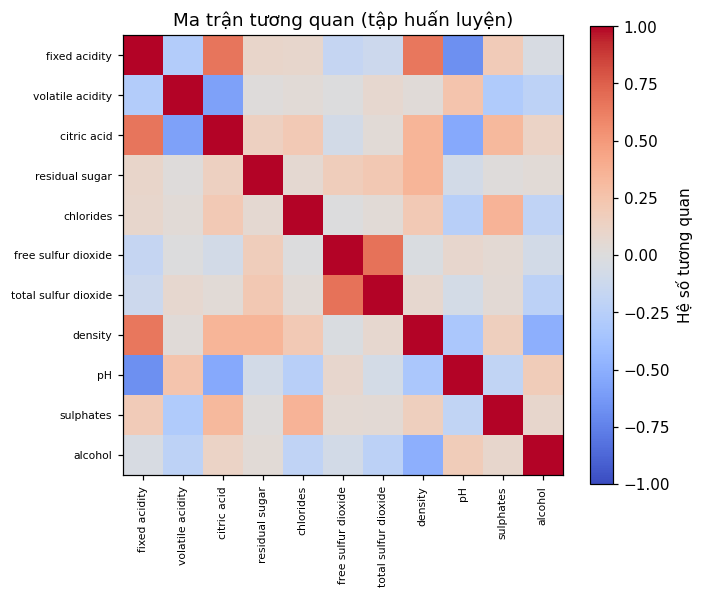


Dac trung bac 2 (77 dac trung): MSE huan luyen=0.3699, MSE kiem tra=0.3924, R2 kiem tra=0.3366
Tuyen tinh (11 dac trung)        : MSE huan luyen=0.4224, MSE kiem tra=0.4018, R2 kiem tra=0.3208

Trung binh du doan theo nhan that (tap kiem tra):
   quality=3 (n=  2): TB du doan = 4.649
   quality=4 (n= 12): TB du doan = 5.684
   quality=5 (n=149): TB du doan = 5.334
   quality=6 (n=126): TB du doan = 5.819
   quality=7 (n= 28): TB du doan = 6.265
   quality=8 (n=  3): TB du doan = 6.443
Phan du: TB=-0.079, do lech chuan=0.629
Lam tron du doan: dung chinh xac 0.631; sai lech <=1 diem 0.966   (moc: luon doan 5 -> 0.466; luon doan 6 -> 0.394)


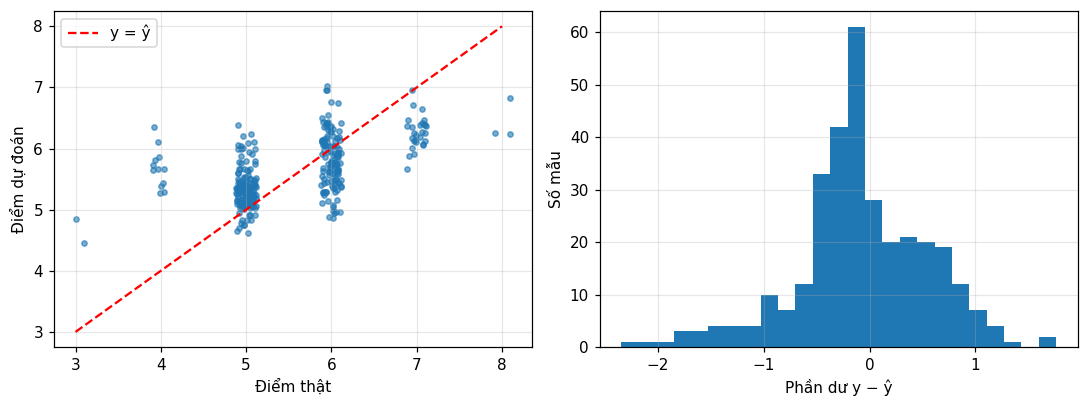

In [13]:
C = np.corrcoef(Xtr, rowvar=False)
iu = np.triu_indices(11, 1)
big = sorted(zip(np.abs(C[iu]), iu[0], iu[1]), reverse=True)[:6]
print("Cac cap dac trung tuong quan manh nhat:")
for _, i_, j_ in big: print(f"   {names[i_]:<22} ~ {names[j_]:<22} r = {C[i_, j_]:+.3f}")
d = names.index("density")
print(f"Ti trong: r(alcohol) = {C[d, names.index('alcohol')]:+.3f},  r(fixed acidity) = {C[d, names.index('fixed acidity')]:+.3f}")
vif = np.diag(np.linalg.inv(C))
print("VIF lon nhat:", ", ".join(f"{names[k]}={vif[k]:.2f}" for k in np.argsort(-vif)[:4]))
plt.figure(figsize=(6.5, 5.5)); plt.imshow(C, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(label="Hệ số tương quan")
plt.xticks(range(11), names, rotation=90, fontsize=7); plt.yticks(range(11), names, fontsize=7); plt.grid(False)
plt.title("Ma trận tương quan (tập huấn luyện)"); plt.tight_layout(); plt.show()

Ptr = poly2_features(standardize_apply(Xtr, m, s)); Pte = poly2_features(standardize_apply(Xte, m, s))
pm, ps = standardize_fit(Ptr)
P1, P2 = add_bias(standardize_apply(Ptr, pm, ps)), add_bias(standardize_apply(Pte, pm, ps))
th_p = normal_equation(P1, ytr)
print(f"\nDac trung bac 2 ({P1.shape[1]-1} dac trung): MSE huan luyen={mse(ytr, P1@th_p):.4f}, MSE kiem tra={mse(yte, P2@th_p):.4f}, R2 kiem tra={r2(yte, P2@th_p):.4f}")
print(f"Tuyen tinh (11 dac trung)        : MSE huan luyen={mse(ytr, Ztr@theta_star):.4f}, MSE kiem tra={mse(yte, yhat):.4f}, R2 kiem tra={r2(yte, yhat):.4f}")

print("\nTrung binh du doan theo nhan that (tap kiem tra):")
for c in np.unique(yte): print(f"   quality={int(c)} (n={int((yte==c).sum()):>3}): TB du doan = {yhat[yte==c].mean():.3f}")
res = yte - yhat; rd = np.clip(np.rint(yhat), 3, 8)
print(f"Phan du: TB={res.mean():+.3f}, do lech chuan={res.std():.3f}")
print(f"Lam tron du doan: dung chinh xac {np.mean(rd==yte):.3f}; sai lech <=1 diem {np.mean(np.abs(rd-yte)<=1):.3f}"
      f"   (moc: luon doan 5 -> {np.mean(yte==5):.3f}; luon doan 6 -> {np.mean(yte==6):.3f})")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(yte + np.random.default_rng(SEED).uniform(-.12, .12, len(yte)), yhat, s=12, alpha=.6)
ax[0].plot([3, 8], [3, 8], "r--", label="y = ŷ"); ax[0].set_xlabel("Điểm thật"); ax[0].set_ylabel("Điểm dự đoán"); ax[0].legend()
ax[1].hist(res, bins=25); ax[1].set_xlabel("Phần dư y − ŷ"); ax[1].set_ylabel("Số mẫu"); plt.tight_layout(); plt.show()

## Đối chiếu tự động với báo cáo
Mỗi dòng so một con số trong `BaoCao.pdf` với kết quả vừa tính. `OK` nếu nằm trong dung sai nêu ở cột cuối.

In [14]:
def row(name, rep, got, rel=None, absol=None):
    ok = (abs(got - rep) <= absol) if absol is not None else (abs(got - rep) <= rel * abs(rep))
    return {"Mục": name, "Báo cáo": rep, "Notebook": got, "Kết quả": "OK" if ok else "LỆCH",
            "Dung sai": f"±{absol}" if absol is not None else f"{rel:.1%}"}

it = lambda h: h["iters_to_tol"]
R = [
 row("MSE mốc (trung bình nhãn)", 0.6040, baseline, absol=5e-5),
 row("λmax (chuẩn hoá)", 3.084, lmax, absol=5e-4),
 row("λmin (chuẩn hoá)", 0.0597, lmin, absol=5e-5),
 row("κ (chuẩn hoá)", 51.6, kappa, absol=0.05),
 row("λmax (thô)", 3.63e3, lmax_r, rel=0.005),
 row("λmin (thô)", 2.82e-7, lmin_r, rel=0.01),
 row("κ (thô)", 1.29e10, kappa_r, rel=0.01),
 row("γmax (chuẩn hoá)", 0.6485, 2/lmax, absol=5e-5),
 row("L(θ*)", 0.2112205, Lstar, absol=5e-7),
 row("‖θ*‖ = ‖θ0−θ*‖", 5.67, e0, absol=0.005),
 row("Số vòng, γ=1/λmax (chuẩn hoá)", 507, it(h_std), absol=0),
 row("Thô: L−L* sau 5000 vòng", 0.030, raw_gap, absol=5e-4),
 row("Thô: ‖θT−θ*‖", 57.4, raw_dist, absol=0.05),
 row("Thô: MSE kiểm tra", 0.5001, raw_mse, absol=5e-5),
 row("MSE kiểm tra tối ưu", 0.4018, raw_opt, absol=5e-5),
 row("Bảng 4: L(θ300) c=0.1", 0.211270, runs[0.1]["loss"][300], absol=5e-7),
 row("Bảng 4: L(θ300) c=0.5", 0.211221, runs[0.5]["loss"][300], absol=5e-7),
 row("Bảng 4: L(θ300) c=1.99", 0.211233, runs[1.99]["loss"][300], absol=5e-7),
 row("Bảng 4: vòng c=0.1", 5114, it(runs[0.1]), absol=0),
 row("Bảng 4: vòng c=0.5", 1019, it(runs[0.5]), absol=0),
 row("Bảng 4: vòng c=1.0", 507, it(runs[1.0]), absol=0),
 row("Bảng 4: vòng c=1.9", 265, it(runs[1.9]), absol=0),
 row("Bảng 4: vòng c=1.99", 1090, it(runs[1.99]), absol=0),
 row("γopt", 0.6362, g_opt, absol=5e-5),
 row("ρopt", 0.9620, rho_opt, absol=5e-5),
 row("γopt: cận lý thuyết (vòng)", 401, bound_opt, absol=1),
 row("γopt: thực đo (vòng)", 285, it(h_opt), absol=0),
 row("γ=1/λmax: cận κ·ln (vòng)", 803, bound_inv, absol=1),
 row("Bảng 5: heavy-ball γ", 0.9995, g_hb, absol=5e-5),
 row("Bảng 5: heavy-ball β", 0.571, b_hb, absol=5e-4),
 row("Bảng 5: √β", 0.756, np.sqrt(b_hb), absol=5e-4),
 row("Bảng 5: vòng β=0.5", 242, it(mruns[1][1]), absol=0),
 row("Bảng 5: vòng β=0.9", 263, it(mruns[2][1]), absol=0),
 row("Bảng 5: vòng heavy-ball", 57, it(mruns[3][1]), absol=0),
 row("Heavy-ball: cận lý thuyết (vòng)", 56, hb_bound, absol=1),
 row("Bảng 6: MSE huấn luyện", 0.4224, mse(ytr, Ztr@th_gd2000), absol=5e-5),
 row("Bảng 6: R² kiểm tra", 0.3208, r2(yte, Zte@th_gd2000), absol=5e-5),
 row("RMSE kiểm tra", 0.634, rmse, absol=5e-4),
 row("Độ lệch chuẩn nhãn", 0.81, y.std(), absol=0.005),
 row("Hệ số cồn", 0.289, coef["alcohol"], absol=5e-4),
 row("Hệ số axit bay hơi", -0.198, coef["volatile acidity"], absol=5e-4),
 row("Hệ số sunfat", 0.148, coef["sulphates"], absol=5e-4),
 row("Hệ số axit cố định", 0.115, coef["fixed acidity"], absol=5e-4),
 row("Hệ số SO2 tổng", -0.102, coef["total sulfur dioxide"], absol=5e-4),
]
chk = pd.DataFrame(R); display(chk)
print(f"\nTong: {(chk['Kết quả']=='OK').sum()}/{len(chk)} muc khop.")

print("\nCac so cung bac sai so may (bao cao ghi ~1e-15):")
print(f"  GD vs chuan tac        : {inf(th_gd2000, theta_star):.1e}   (bao cao 3.7e-15)")
print(f"  Heavy-ball vs chuan tac: {inf(th_hb2000, theta_star):.1e}   (bao cao 4.0e-15)")
print(f"  sklearn vs chuan tac   : {inf(th_sk, theta_star):.1e}   (bao cao 4.2e-15)")
print(f"  GD vs sklearn          : {gd_vs_sk:.1e}   (bao cao 8.9e-16)")
assert max(inf(th_gd2000, theta_star), inf(th_hb2000, theta_star), inf(th_sk, theta_star), gd_vs_sk) < 1e-13

,Mục,Báo cáo,Notebook,Kết quả,Dung sai
0,MSE mốc (trung bình nhãn),6.040000e-01,6.039742e-01,OK,±5e-05
1,λmax (chuẩn hoá),3.084000e+00,3.083898e+00,OK,±0.0005
2,λmin (chuẩn hoá),5.970000e-02,5.972950e-02,OK,±5e-05
3,κ (chuẩn hoá),5.160000e+01,5.163107e+01,OK,±0.05
4,λmax (thô),3.630000e+03,3.629939e+03,OK,0.5%
5,λmin (thô),2.820000e-07,2.817963e-07,OK,1.0%
6,κ (thô),1.290000e+10,1.288143e+10,OK,1.0%
7,γmax (chuẩn hoá),6.485000e-01,6.485299e-01,OK,±5e-05
8,L(θ*),2.112205e-01,2.112205e-01,OK,±5e-07
9,‖θ*‖ = ‖θ0−θ*‖,5.670000e+00,5.674676e+00,OK,±0.005



Tong: 44/44 muc khop.

Cac so cung bac sai so may (bao cao ghi ~1e-15):
  GD vs chuan tac        : 8.9e-16   (bao cao 3.7e-15)
  Heavy-ball vs chuan tac: 8.9e-16   (bao cao 4.0e-15)
  sklearn vs chuan tac   : 8.0e-16   (bao cao 4.2e-15)
  GD vs sklearn          : 8.9e-16   (bao cao 8.9e-16)
